# WT3 against GD1 under six positivity rules

**Question.** Do we reach the same conclusions about AF488+ cells whichever "median + k SD" rule calls them positive?

**The rules.** A cell is AF488+ when its value is above the median + k robust SDs of the junction region's cells, in the same section (the run's way). Two values × three k:

| value | what it is |
|---|---|
| **raw** | the cell's AF488 mean |
| **median filter** | the cell's AF488 mean less the local median (45 µm) — the run's value; k = 7 is the run's rule |

**What is compared, per genotype** (one dot per section):

1. **Crossed cells** — AF488+ cells 2–300 µm past the junction line, in the organoid where AF488 is not at home: the number, and per mm of junction line.
2. **Cells in the junction** — AF488+ cells in the junction region (the counted strip): the number, and per mm of junction line.
3. **Distance of the crossed cells to the organoid edge** — the mean, per section, of the crossed cells' distance to the tissue edge (µm; small = along the surface).
4. **Distance to the edge against distance past the line** — do the cells that travel further stay at the surface? The cells pooled per genotype (binned means), and per section the slope of edge distance on distance past the line.

**Statistics.** Graphs show sections. The test is a mixed model with slide as a random effect (sections on a slide may come from one assembloid) and experiment as a fixed effect: for counts the fold change WT3 / GD1 on log(1 + y), for distances the difference WT3 − GD1 in µm. The last section puts every rule and outcome in one table: same direction, same side of p = 0.05 → same conclusion.

**Data.** The cells-analysis run `cells_analysis\2026-10-28_090440 re-scored` (614 sections), read from the slim cell cache that `03_cells_run.ipynb` writes (`run_analysis_20261028\cache`); if the cache is missing it is built here (a few minutes). Settings, rules and outcomes are in the next cells — change them there.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

# ---------------------------------------------------------------- Settings: change these
RUN = Path(r"D:\Slidescanner extracted\cells_analysis\2026-10-28_090440 re-scored")
OUT = Path(r"D:\Slidescanner extracted\run_analysis_20261028")
CACHE = OUT / "cache"                     # shared with 03_cells_run.ipynb
FIGURES = OUT / "figures_genotype"
DESIGN_CSV = Path(r"D:\Slidescanner extracted\Image_File_List.csv")

CHANNEL = "AF488"
GAP_UM = 2.0          # the first µm past the line count as neither side
NEAR_UM = 300.0       # crossed: up to this far past the line
KEEP_UM = 650.0       # cells kept in the cache, from the line
MIN_EDGE = 3          # a section's edge figures need at least this many crossed cells
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)
GENOTYPES = ["WT3", "GD1"]
REFERENCE, OTHER = "GD1", "WT3"        # differences and folds are WT3 against GD1

**Style.** Prism-like: thick black axes, every dot, bar and curve edged in black, WT3 blue and GD1 orange throughout. `dots_and_bar` draws one panel; change the look there.

In [2]:
GENOTYPE_COLOURS = {"WT3": "#2a78d6", "GD1": "#eb6834"}
EDGE = dict(edgecolor="black", linewidth=1.1)
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.labelweight": "bold", "axes.linewidth": 1.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.8, "ytick.major.width": 1.8, "xtick.major.size": 6, "ytick.major.size": 6,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "svg.fonttype": "none",
})


def save(fig, name):
    if SAVE_FIGURES:
        for ext in ("svg", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def stars(p):
    return "ns" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"


def dots_and_bar(ax, frame, column, p=None, log=False, seed=0):
    """Bar = mean ± SEM per genotype (black edge), every section as a black-edged dot, bracket with the p."""
    rng = np.random.default_rng(seed)
    top = 0.0
    for k, g in enumerate(GENOTYPES):
        y = pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").dropna().to_numpy()
        if not len(y):
            continue
        top = max(top, y.max())
        ax.bar(k, y.mean(), width=0.62, color=GENOTYPE_COLOURS[g], alpha=0.35, zorder=1, **EDGE)
        ax.errorbar(k, y.mean(), yerr=y.std(ddof=1) / np.sqrt(len(y)), color="black", capsize=7, capthick=1.8,
                    lw=1.8, zorder=4)
        ax.scatter(k + rng.uniform(-0.2, 0.2, len(y)), y, s=12, color=GENOTYPE_COLOURS[g], alpha=0.75, zorder=3,
                   edgecolor="black", linewidth=0.5)
    counts = [int(pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").notna().sum())
              for g in GENOTYPES]
    ax.set_xticks(range(len(GENOTYPES)), [f"{g}\n(n={n})" for g, n in zip(GENOTYPES, counts)])
    ax.set_xlim(-0.6, len(GENOTYPES) - 0.4)
    if log:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    if p is not None:
        y0 = top * (1.5 if log else 1.06)
        ax.plot([0, 0, 1, 1], [y0 * 0.96, y0, y0, y0 * 0.96], color="black", lw=1.5)
        ax.text(0.5, y0 * (1.06 if log else 1.01), f"{stars(p)} (p = {p:.2g})", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(top=y0 * (2.4 if log else 1.14))

## 1. The sections and their cells

From the run: each section's junction length (`cells/<sample>.json`) and its genotype, experiment and slide (file list). From the cache: each cell's position (in the junction region or not, distance to the line, beside it or past its ends, distance to the tissue edge) and its AF488 values.

In [3]:
def read_section(path):
    info = json.loads(path.read_text(encoding="utf-8"))
    return {"name": info["sample"], "length (mm)": info.get("junction_length_um", np.nan) / 1000}


sections = pd.DataFrame([read_section(p) for p in sorted((RUN / "cells").glob("*.json"))])
design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)
sections = sections.merge(design[["name", "Genotype", "Experiment", "slide"]], on="name").set_index("name")

KEEP_COLUMNS = {
    "Label": "label", "Centroid Y (µm)": "y", "Centroid X (µm)": "x", "Nucleus area (µm²)": "area",
    "In region": "region", "Distance to the junction line (µm)": "d", "Beside the junction line": "beside",
    "Distance to the tissue edge (µm)": "edge",
    **{f"{ch} {what}": f"{ch} {what}" for ch in ("AF488", "AF555")
       for what in ("mean", "P95", "ring mean", "ring contrast", "mean (median filter)", "positive")},
}


def slim(name):
    """The kept cells of one section: from the cache (03_cells_run), else read from the run and cached."""
    target = CACHE / f"{name}.parquet"
    if target.exists():
        return pd.read_parquet(target)
    CACHE.mkdir(parents=True, exist_ok=True)
    table = pacsv.read_csv(RUN / "cells" / f"{name}.csv",
                           convert_options=pacsv.ConvertOptions(include_columns=list(KEEP_COLUMNS))).to_pandas()
    table = table.rename(columns=KEEP_COLUMNS)
    table = table[table["region"] | (table["beside"] & (table["d"].abs() <= KEEP_UM))].reset_index(drop=True)
    table.to_parquet(target, index=False)
    return table


cells = {name: slim(name) for name in sections.index}

# Which side of the line is AF488's home: the side with most of the run's AF488+ cells.
# `away` is then the distance into the other organoid (+ = past the line, where crossed cells are).
for name, c in cells.items():
    pos = c[f"{CHANNEL} positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
    c["away"] = c["d"] * sign
print(f"{len(sections)} sections on {sections['slide'].nunique()} slides; "
      + ", ".join(f"{g}: {int((sections['Genotype'] == g).sum())}" for g in GENOTYPES))

614 sections on 36 slides; WT3: 265, GD1: 349


## 2. The rules

Each rule's bar is the median + k × the robust SD (1.4826 × MAD) of the **junction region's cells** of the same section, on the raw mean or the median-filtered mean. To add a rule, add a line to `RULES`: `(value column, k)`.

In [4]:
RAW, FILTERED = f"{CHANNEL} mean", f"{CHANNEL} mean (median filter)"
RULES = {
    "raw · median + 3 SD": (RAW, 3.0),
    "raw · median + 5 SD": (RAW, 5.0),
    "raw · median + 7 SD": (RAW, 7.0),
    "median filter · median + 3 SD": (FILTERED, 3.0),
    "median filter · median + 5 SD": (FILTERED, 5.0),
    "median filter · median + 7 SD (run)": (FILTERED, 7.0),
}
RULE_NAMES = list(RULES)


def robust(values):
    v = np.asarray(values, np.float64)
    v = v[np.isfinite(v)]
    if not v.size:
        return np.nan, np.nan
    centre = float(np.median(v))
    return centre, float(np.median(np.abs(v - centre)) * 1.4826)


def positive(c, rule):
    value, k = RULES[rule]
    centre, sd = robust(c.loc[c["region"], value])
    return (c[value] > centre + k * sd).to_numpy()


check = sum(int((positive(cells[n], "median filter · median + 7 SD (run)") != cells[n][f"{CHANNEL} positive"]).sum())
            for n in sections.index)
print(f"the run's rule recomputed: {check} cells called differently from the run (0 expected)")

the run's rule recomputed: 0 cells called differently from the run (0 expected)


## 3. The outcomes, per section and rule

In [5]:
records, crossed_cells = [], []
for name, s in sections.iterrows():
    c = cells[name]
    away, beside, edge = c["away"].to_numpy(), c["beside"].to_numpy(bool), c["edge"].to_numpy(float)
    crossed_zone = beside & (away > GAP_UM) & (away <= NEAR_UM)
    region = c["region"].to_numpy(bool)
    for rule in RULE_NAMES:
        pos = positive(c, rule)
        crossed = pos & crossed_zone
        n_crossed = int(crossed.sum())
        depth, side = away[crossed], edge[crossed]
        slope = np.polyfit(depth, side, 1)[0] if n_crossed >= MIN_EDGE and np.ptp(depth) > 0 else np.nan
        records.append({
            "name": name, "rule": rule, "Genotype": s["Genotype"], "Experiment": s["Experiment"], "slide": s["slide"],
            "crossed cells": n_crossed,
            "crossed per mm": n_crossed / s["length (mm)"],
            "cells in junction": int((pos & region).sum()),
            "in junction per mm": int((pos & region).sum()) / s["length (mm)"],
            "crossed: mean distance to edge (µm)": side.mean() if n_crossed >= MIN_EDGE else np.nan,
            "crossed: edge vs line slope": slope,
        })
        crossed_cells.append(pd.DataFrame({"rule": rule, "Genotype": s["Genotype"], "name": name,
                                           "past the line (µm)": depth, "to the edge (µm)": side}))
obs = pd.DataFrame(records)
crossed_cells = pd.concat(crossed_cells, ignore_index=True)
print(f"{len(obs)} rows: {len(sections)} sections × {len(RULE_NAMES)} rules")
display(obs.groupby(["rule", "Genotype"])[["crossed cells", "crossed per mm", "cells in junction", "in junction per mm",
                                            "crossed: mean distance to edge (µm)", "crossed: edge vs line slope"]]
        .median().round(2).loc[RULE_NAMES])

3684 rows: 614 sections × 6 rules


crossed cells  crossed per mm  cells in junction  in junction per mm  crossed: mean distance to edge (µm)  crossed: edge vs line slope
rule                                Genotype                                                                                                                                        
raw · median + 3 SD                 GD1                87.0           77.60               96.0               85.80                               331.01                        -0.06
                                    WT3               131.0          142.21              165.0              168.15                               224.24                         0.22
raw · median + 5 SD                 GD1                 7.0            5.94                7.0                6.42                               318.83                        -0.10
                                    WT3                24.0           26.06               28.0               34.58                               187.25                         0.19
raw · median + 7 SD                 GD1                 1.0            1.04                1.0                1.18                               264.98                        -0.06
                                    WT3                 7.0            7.46               11.0                9.80                               169.69                         0.26
median filter · median + 3 SD       GD1               101.0           86.33              104.0               89.72                               317.61                         0.01
                                    WT3               113.0          115.09              134.0              137.12                               244.00                         0.29
median filter · median + 5 SD       GD1                21.0           19.36               22.0               20.12                               309.25                         0.02
                                    WT3                41.0           40.63               46.0               48.03                               220.11                         0.27
median filter · median + 7 SD (run) GD1                 8.0            7.51                9.0                8.28                               293.71                        -0.07
                                    WT3                21.0           24.21               26.0               26.98                               207.97                         0.23

## 4. The mixed model

For every rule and outcome: counts on log(1 + y) → **fold WT3 / GD1**; distances and the slope as they are → **difference WT3 − GD1**. Slide random, experiment fixed.

In [6]:
OUTCOMES = {  # outcome → ("fold" for counts on log(1 + y), "difference" for µm or slope), axis label
    "crossed cells": ("fold", "AF488+ cells that crossed\n(per section)"),
    "crossed per mm": ("fold", "AF488+ cells that crossed\n(per mm of junction)"),
    "cells in junction": ("fold", "AF488+ cells in the junction region\n(per section)"),
    "in junction per mm": ("fold", "AF488+ cells in the junction region\n(per mm of junction)"),
    "crossed: mean distance to edge (µm)": ("difference", "crossed cells: mean distance\nto the organoid edge (µm)"),
    "crossed: edge vs line slope": ("difference", "crossed cells: µm further from the edge\nper µm further past the line"),
}
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER}]"


def mixed(frame, column, kind):
    d = frame[["Genotype", "Experiment", "slide"]].copy()
    y = pd.to_numeric(frame[column], errors="coerce")
    d["y"] = np.log1p(y) if kind == "fold" else y
    d = d.dropna()
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", d, groups=d["slide"]).fit(reml=True)
    est, (lo, hi) = fit.params[TERM], fit.conf_int().loc[TERM]
    if kind == "fold":
        est, lo, hi = np.exp(est), np.exp(lo), np.exp(hi)
    return {"effect": est, "CI low": lo, "CI high": hi, "p": fit.pvalues[TERM], "sections": len(d)}


effects = pd.DataFrame([{"rule": rule, "outcome": outcome, "kind": kind,
                         **mixed(obs[obs["rule"] == rule], outcome, kind)}
                        for rule in RULE_NAMES for outcome, (kind, _label) in OUTCOMES.items()])
display(effects.set_index(["outcome", "rule"]).round(3))

,,kind,effect,CI low,CI high,p,sections
outcome,rule,,,,,,
crossed cells,raw · median + 3 SD,fold,1.615,0.920,2.834,0.095,614
crossed per mm,raw · median + 3 SD,fold,1.839,1.124,3.008,0.015,614
cells in junction,raw · median + 3 SD,fold,1.763,1.008,3.083,0.047,614
in junction per mm,raw · median + 3 SD,fold,1.999,1.219,3.278,0.006,614
crossed: mean distance to edge (µm),raw · median + 3 SD,difference,-81.555,-128.706,-34.404,0.001,600
crossed: edge vs line slope,raw · median + 3 SD,difference,0.285,0.121,0.449,0.001,600
crossed cells,raw · median + 5 SD,fold,2.624,1.680,4.101,0.000,614
crossed per mm,raw · median + 5 SD,fold,3.049,1.902,4.886,0.000,614
cells in junction,raw · median + 5 SD,fold,2.866,1.797,4.572,0.000,614


## 5. Crossed cells, by genotype

Top row: the number of AF488+ cells past the line per section; bottom row: the same per mm of junction line. One column per rule; one dot per section; bar = mean ± SEM; p from the mixed model.

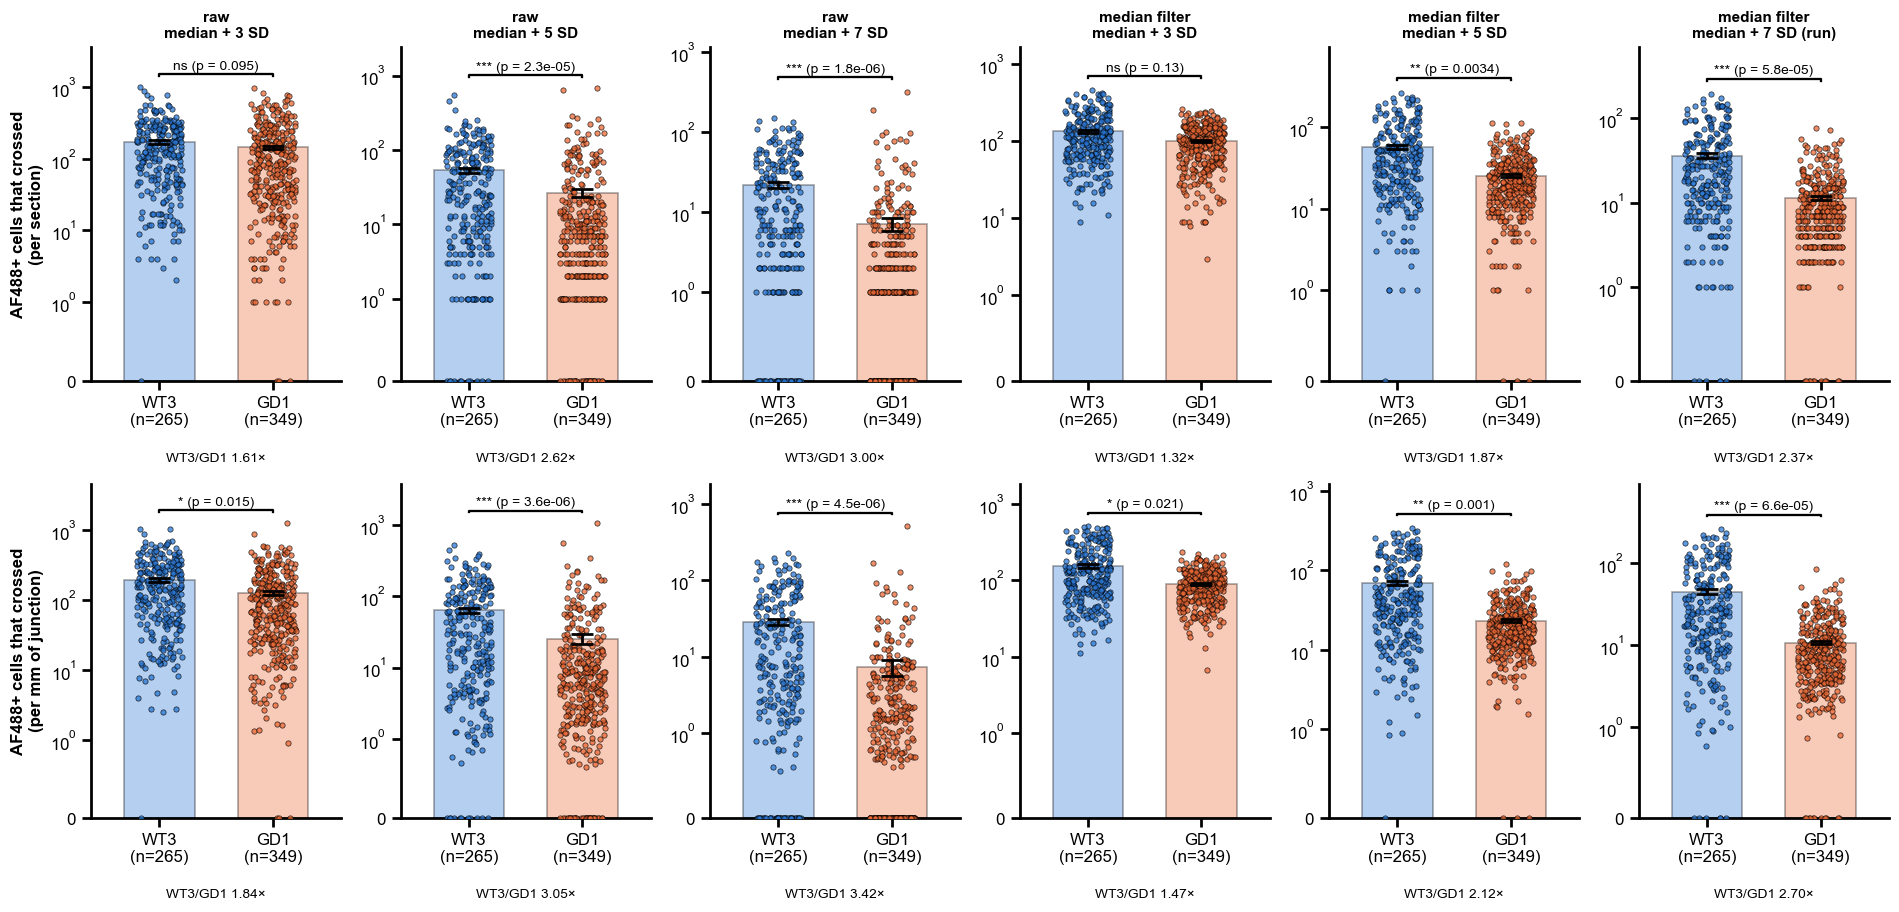

In [7]:
def grid(outcomes, name, log=True):
    fig, axes = plt.subplots(len(outcomes), len(RULE_NAMES), figsize=(2.9 * len(RULE_NAMES), 4.2 * len(outcomes)),
                             squeeze=False)
    for i, outcome in enumerate(outcomes):
        for j, rule in enumerate(RULE_NAMES):
            ax = axes[i, j]
            e = effects[(effects["rule"] == rule) & (effects["outcome"] == outcome)].iloc[0]
            dots_and_bar(ax, obs[obs["rule"] == rule], outcome, p=e["p"], log=log)
            if i == 0:
                ax.set_title(rule.replace(" · ", "\n"), fontsize=10)
            if j == 0:
                ax.set_ylabel(OUTCOMES[outcome][1])
            sign = "×" if e["kind"] == "fold" else " µm"
            ax.text(0.5, -0.24, f"WT3/GD1 {e['effect']:.2f}{sign}" if e["kind"] == "fold"
                    else f"WT3 − GD1 {e['effect']:+.1f}{sign}", transform=ax.transAxes, ha="center", fontsize=9)
    fig.tight_layout()
    save(fig, name)
    plt.show()


grid(["crossed cells", "crossed per mm"], "crossed_cells")

## 6. AF488+ cells in the junction region, by genotype

The same for the cells in the junction region (the counted strip on the far side of the line): the number per section, and per mm of junction line.

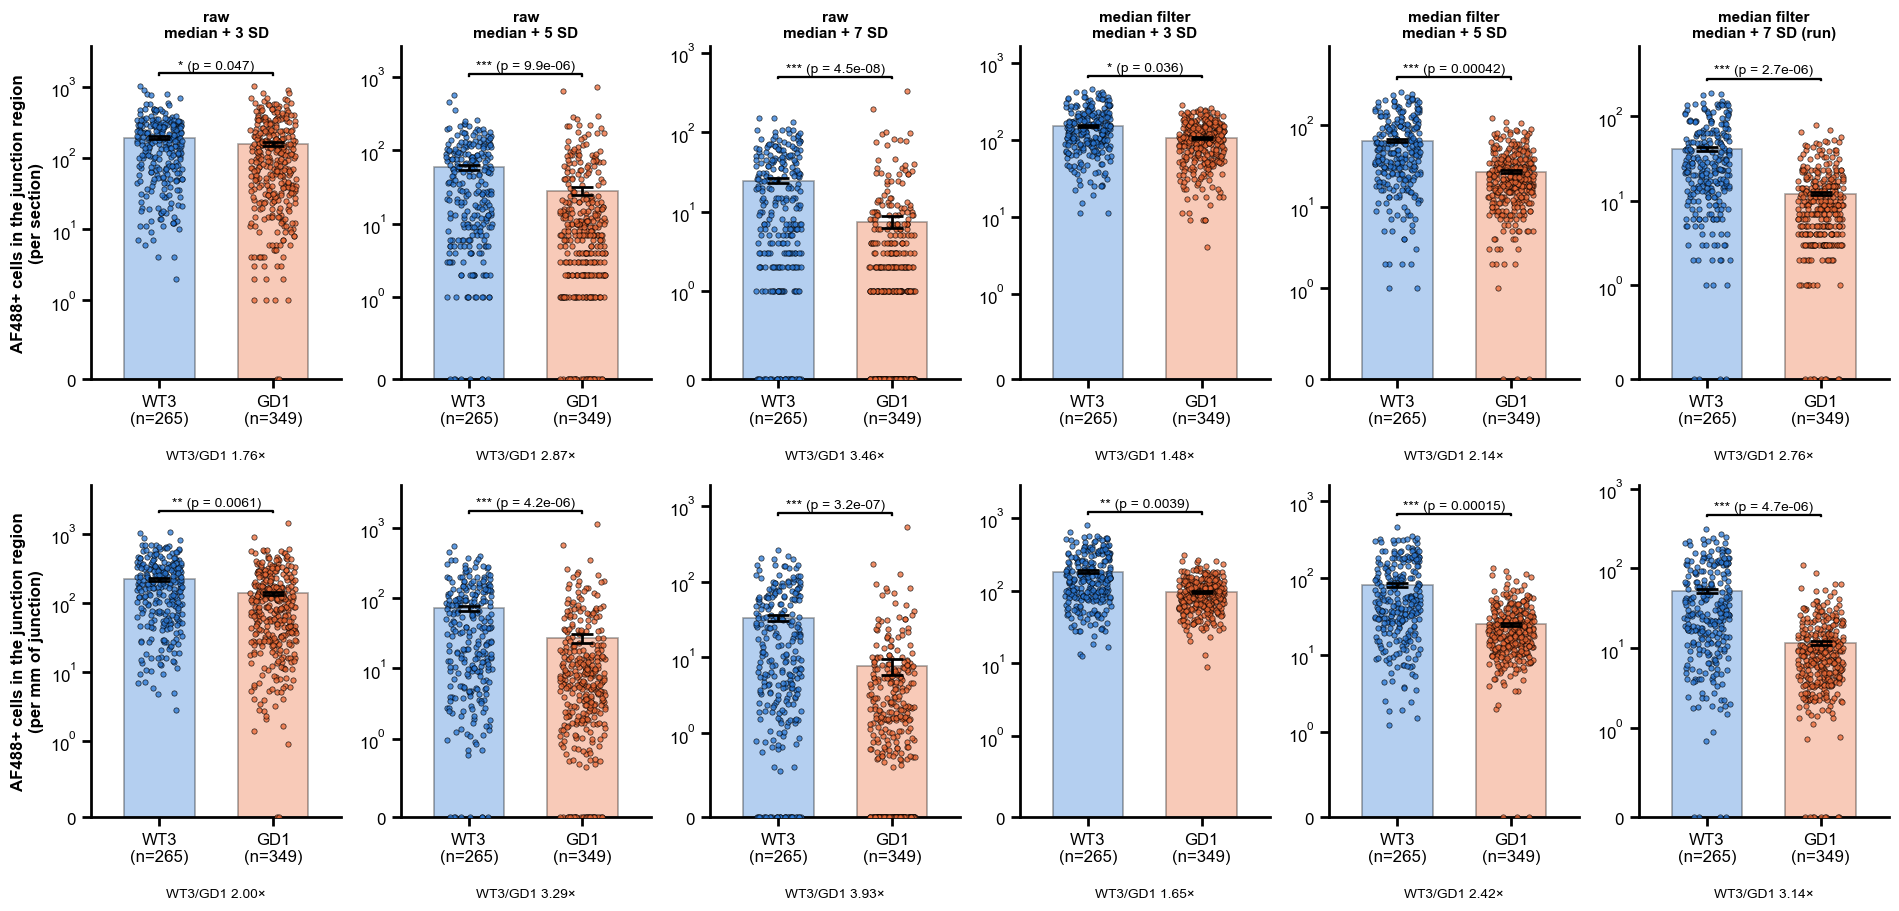

In [8]:
grid(["cells in junction", "in junction per mm"], "junction_cells")

## 7. How far the crossed cells are from the organoid edge

Per section, the mean distance to the tissue edge of its crossed AF488+ cells (sections with at least `MIN_EDGE` of them). Smaller = nearer the surface.

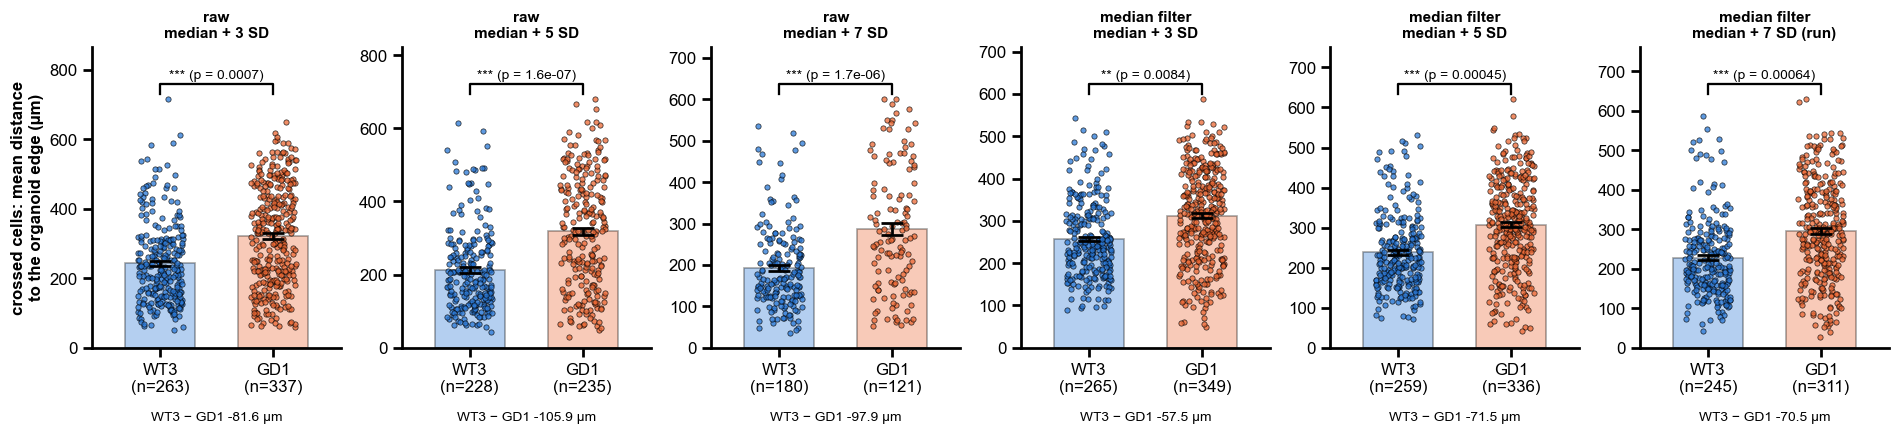

In [9]:
grid(["crossed: mean distance to edge (µm)"], "crossed_edge_distance", log=False)

## 8. Distance to the edge against distance past the line

Do the cells that went further stay on the surface? Top: every crossed AF488+ cell pooled per genotype, binned by distance past the line (25 µm bins): mean distance to the edge ± SEM. A rising curve: the further a cell went, the deeper into the tissue it is; a flat one: depth past the line does not matter. Bottom: per section (at least `MIN_EDGE` crossed cells), the slope of the same — µm further from the edge per µm further past the line (0 = flat) — with the mixed model's p. The y axis is cut at the 2nd and 98th percentiles; a few extreme slopes (sections with 3–4 crossed cells) are off the panel.

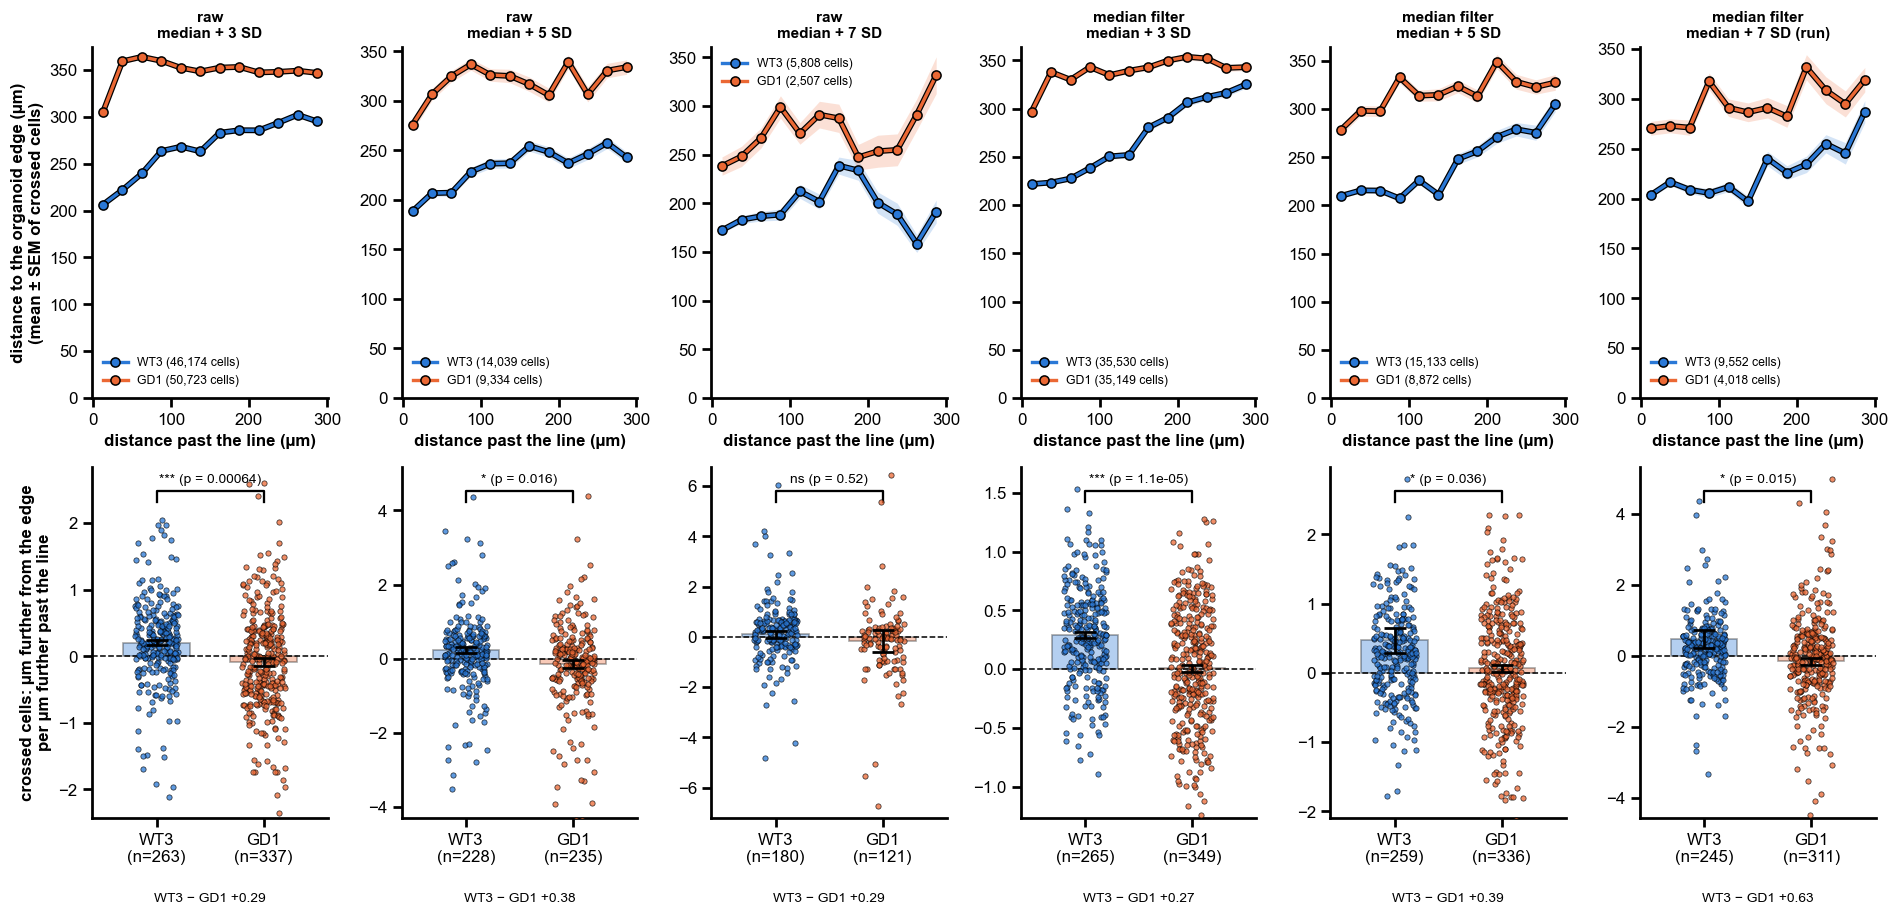

In [10]:
BINS = np.arange(0, NEAR_UM + 1, 25)
centres = (BINS[:-1] + BINS[1:]) / 2
fig, axes = plt.subplots(2, len(RULE_NAMES), figsize=(2.9 * len(RULE_NAMES), 8.4), squeeze=False)
for j, rule in enumerate(RULE_NAMES):
    ax = axes[0, j]
    part = crossed_cells[crossed_cells["rule"] == rule]
    for g in GENOTYPES:
        cg = part[part["Genotype"] == g]
        b = np.digitize(cg["past the line (µm)"], BINS) - 1
        stat = cg.groupby(b)["to the edge (µm)"].agg(["mean", "sem", "size"]).reindex(range(len(centres)))
        stat = stat[stat["size"] >= 10]
        x = centres[stat.index]
        ax.fill_between(x, stat["mean"] - stat["sem"], stat["mean"] + stat["sem"], color=GENOTYPE_COLOURS[g],
                        alpha=0.2, lw=0)
        ax.plot(x, stat["mean"], color="black", lw=3.8, zorder=2)
        ax.plot(x, stat["mean"], color=GENOTYPE_COLOURS[g], lw=2.2, marker="o", ms=6, mec="black", mew=1,
                zorder=3, label=f"{g} ({len(cg):,} cells)")
    ax.set_title(rule.replace(" · ", "\n"), fontsize=10)
    ax.set_xlabel("distance past the line (µm)")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
    if j == 0:
        ax.set_ylabel("distance to the organoid edge (µm)\n(mean ± SEM of crossed cells)")
    e = effects[(effects["rule"] == rule) & (effects["outcome"] == "crossed: edge vs line slope")].iloc[0]
    ax = axes[1, j]
    dots_and_bar(ax, obs[obs["rule"] == rule], "crossed: edge vs line slope")
    ax.axhline(0, color="black", lw=1, ls="--")
    lo, hi = obs.loc[obs["rule"] == rule, "crossed: edge vs line slope"].quantile([0.02, 0.98])
    ax.set_ylim(lo - 0.3 * abs(lo), hi + 0.6 * abs(hi))       # the few extreme slopes are off the panel
    ax.plot([0, 0, 1, 1], [0.9, 0.93, 0.93, 0.9], color="black", lw=1.5, transform=ax.get_xaxis_transform())
    ax.text(0.5, 0.945, f"{stars(e['p'])} (p = {e['p']:.2g})", ha="center", va="bottom", fontsize=9,
            transform=ax.get_xaxis_transform())
    ax.text(0.5, -0.24, f"WT3 − GD1 {e['effect']:+.2f}", transform=ax.transAxes, ha="center", fontsize=9)
    if j == 0:
        axes[1, j].set_ylabel(OUTCOMES["crossed: edge vs line slope"][1])
fig.tight_layout()
save(fig, "edge_vs_line")
plt.show()

## 9. Same conclusions?

One cell per rule and outcome: the effect (fold WT3 / GD1, or difference WT3 − GD1) and the mixed model's stars. Blue = the figure is higher in WT3, orange = higher in GD1 — for the edge distance orange means WT3's crossed cells are *nearer* the edge; for the slope blue means WT3's crossed cells move away from the edge faster as they go further. Pale = not significant. Read a column down: if the colour and the stars hold, the rule does not change the conclusion.

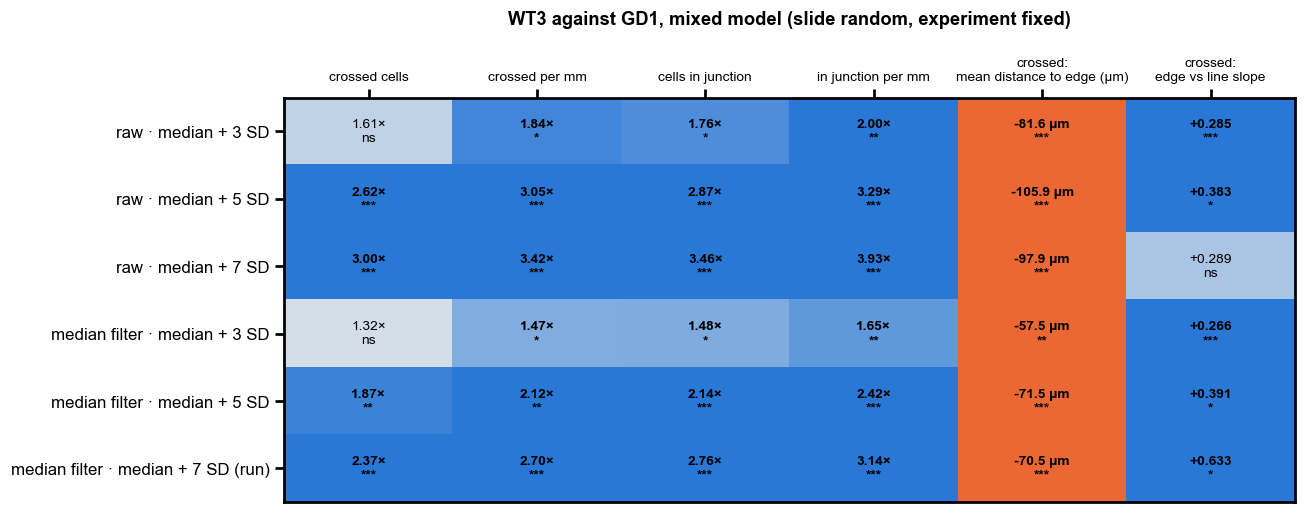

In [11]:
table = effects.pivot(index="rule", columns="outcome", values="effect").loc[RULE_NAMES, list(OUTCOMES)]
pvals = effects.pivot(index="rule", columns="outcome", values="p").loc[RULE_NAMES, list(OUTCOMES)]
signed = pd.DataFrame({o: (np.log2(table[o]) if OUTCOMES[o][0] == "fold" else np.sign(table[o]))
                       for o in OUTCOMES}).loc[RULE_NAMES]
shade = np.clip(signed.to_numpy(float), -1, 1) * np.where(pvals.to_numpy() < 0.05, 1.0, 0.35)
cmap = mpl.colors.LinearSegmentedColormap.from_list("g", [GENOTYPE_COLOURS["GD1"], "#f0efec", GENOTYPE_COLOURS["WT3"]])
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.imshow(shade, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
for i in range(len(RULE_NAMES)):
    for j, o in enumerate(OUTCOMES):
        v, p = table.iat[i, j], pvals.iat[i, j]
        text = f"{v:.2f}×" if OUTCOMES[o][0] == "fold" else f"{v:+.1f}" + ("" if "slope" in o else " µm")
        if "slope" in o:
            text = f"{v:+.3f}"
        ax.text(j, i, f"{text}\n{stars(p)}", ha="center", va="center", fontsize=9,
                fontweight="bold" if p < 0.05 else "normal")
ax.set_xticks(range(len(OUTCOMES)), [o.replace(": ", ":\n") for o in OUTCOMES], fontsize=9)
ax.set_yticks(range(len(RULE_NAMES)), RULE_NAMES)
ax.xaxis.tick_top()
for side in ax.spines.values():
    side.set_visible(True)
ax.set_title("WT3 against GD1, mixed model (slide random, experiment fixed)", pad=48)
fig.tight_layout()
save(fig, "conclusions")
plt.show()

## What it showed (29 October 2026: 614 sections, 36 slides — 265 WT3, 349 GD1)

**Same conclusions under all six rules; only the size of the difference changes.**

- **Crossed AF488+ cells: more in WT3 under every rule.**
  - Per mm of junction: 1.5–3.4×, significant under all six (p 0.001–0.02).
  - Per section: 1.3–3.0×, significant except under the two lenient rules. Raw + 3 SD gives 1.6× (p 0.095), median filter + 3 SD 1.3× (p 0.13).
  - Per mm is the fairer measure: sections differ in how much junction they cut.
- **AF488+ cells in the junction region: more in WT3 under every rule.** 1.5–3.5× per section, 1.6–3.9× per mm, all p < 0.05.
- **The stricter the rule, the bigger the difference** (median filter: 1.5× → 2.1× → 2.7× per mm at 3, 5, 7 SD). A lenient bar also calls background cells, about equally in both genotypes, which dilutes the fold. Raw + 3 SD calls ~100 crossed cells per section in both genotypes, against ~10–20 with the run's rule. Those are mostly not labelled cells.
- **Crossed cells lie nearer the organoid edge in WT3**: 58–106 µm nearer on average under every rule (p ≤ 0.008). Per section the mean distance is about 210–245 µm in WT3 against 295–330 µm in GD1.
- **Edge against distance past the line.** WT3's crossed cells hug the surface just past the line (~200–220 µm from the edge) and lie deeper the further they went: the slope is +0.2–0.3 µm per µm. GD1's sit deeper from the start (~300–350 µm) and the slope is flat (−0.1 to 0). The difference is significant under five rules. Under raw + 7 SD it is not (p 0.52): there only 180 WT3 and 121 GD1 sections have 3 or more crossed cells.

**Read with care.**
- More crossed cells in WT3 goes with more AF488+ cells near the line on WT3's own side (`03_cells_run`, sections 6 and 9). The share of labelled cells that crossed is the same in both genotypes, so these counts say "more labelled cells", not "more migration".
- The edge-distance result is the one that differs in kind: WT3's migrants travel along the surface, GD1's do not.
- "Edge" is the nearest tissue edge in a 2D section, so it includes cut faces and tears.